模型加载完成。
参考密度矩阵尺寸: 184 × 184

预测的混合权重：
[0.24970198 0.26478398 0.22143234 0.26408166]

预测的均值，非负训练坐标系：
[[14.603271 10.298109]
 [10.143091  5.947347]
 [ 5.594977 10.299491]
 [10.148902 14.655641]]

预测的协方差矩阵：
[[[ 6.9114394e-02 -6.9979746e-05]
  [-6.9979746e-05  7.1230903e-02]]

 [[ 7.3939294e-02 -4.9494887e-03]
  [-4.9494887e-03  7.2500385e-02]]

 [[ 6.5628998e-02 -1.0660304e-04]
  [-1.0660304e-04  6.4061955e-02]]

 [[ 7.4351445e-02  5.7048840e-03]
  [ 5.7048840e-03  7.3089302e-02]]]

Hellinger distance = 0.048480

预测的均值，平移回原始坐标系后：
[[ 4.3032703e+00 -1.8911362e-03]
 [-1.5690899e-01 -4.3526530e+00]
 [-4.7050233e+00 -5.0926208e-04]
 [-1.5109825e-01  4.3556404e+00]]

PDF 文件已保存为: landscape_test_200.pdf


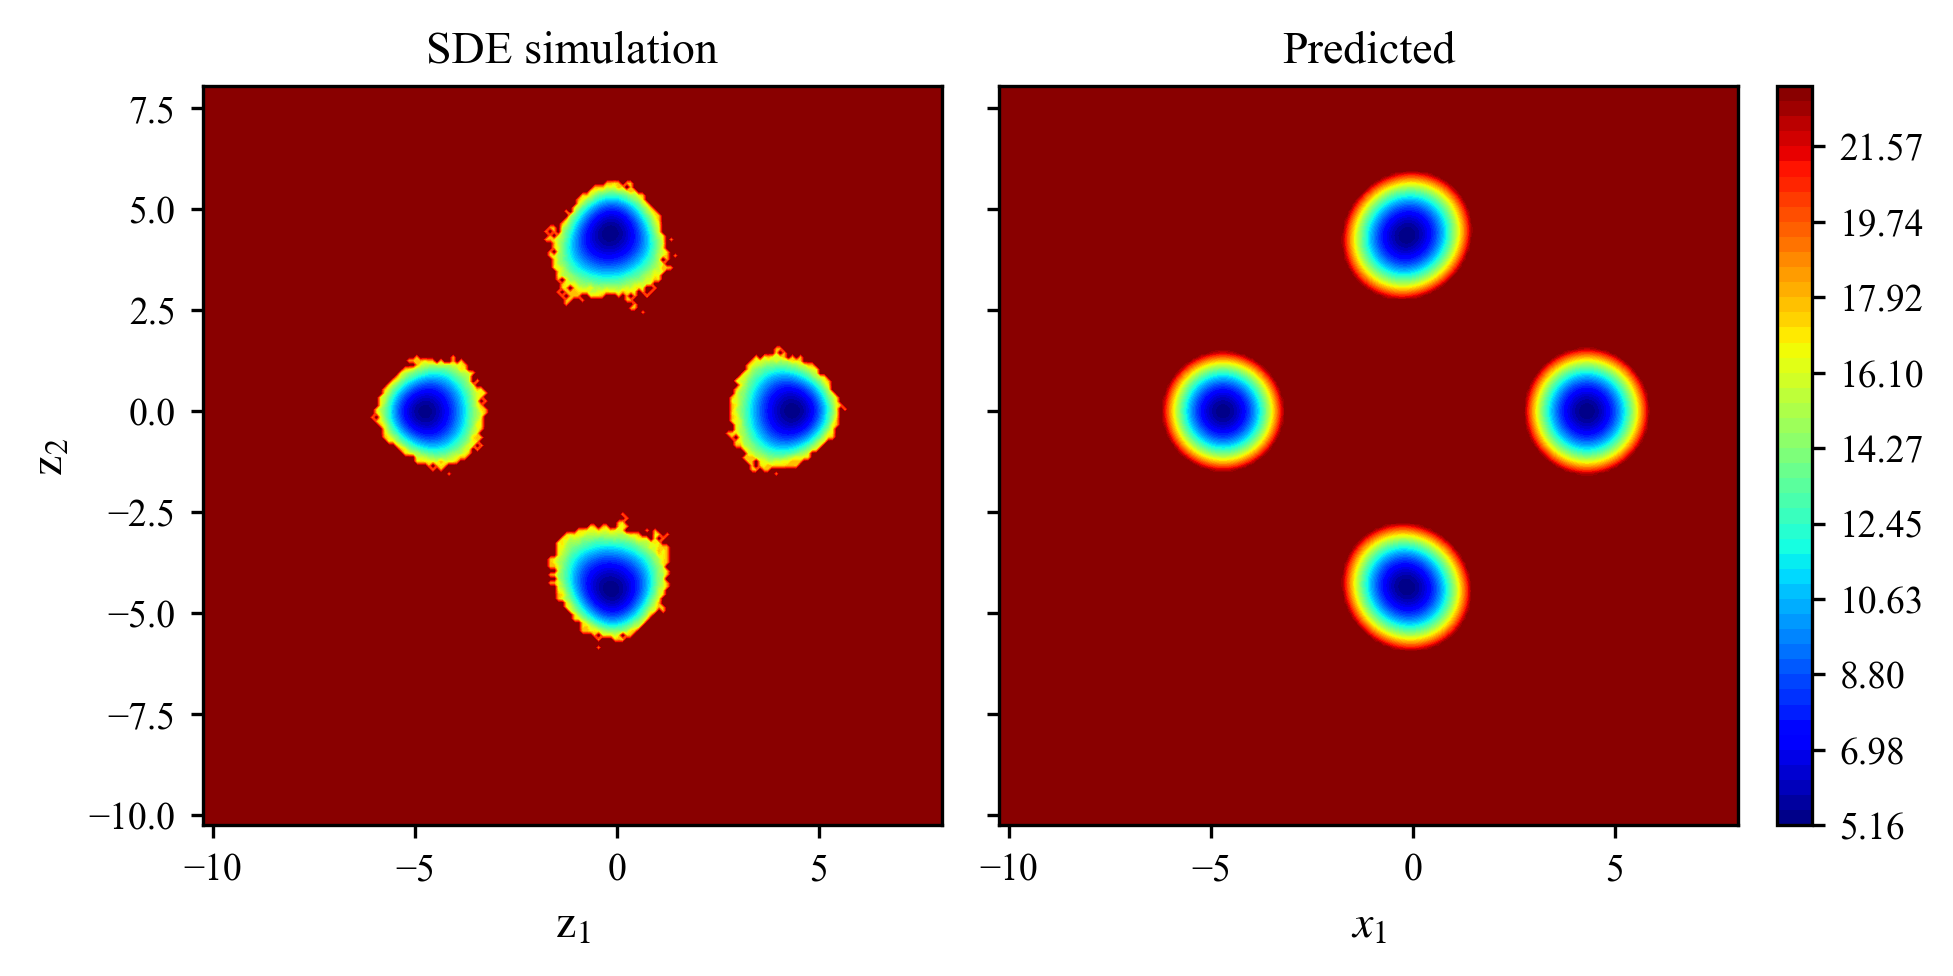

In [6]:
import torch
import torch.nn as nn
import torch.nn.functional as F


# ============================================================
# 1. 定义模型
# ============================================================
class MixtureOfGaussiansModel(nn.Module):
    def __init__(
        self,
        input_dim=5,
        num_components=4,
        hidden_dims=None
    ):
        super(MixtureOfGaussiansModel, self).__init__()

        if hidden_dims is None:
            hidden_dims = [512, 1024, 512]

        self.input_dim = input_dim
        self.num_components = num_components

        self.hidden_layers = nn.ModuleList()

        self.hidden_layers.append(
            nn.Linear(input_dim, hidden_dims[0])
        )

        for i in range(1, len(hidden_dims)):
            self.hidden_layers.append(
                nn.Linear(
                    hidden_dims[i - 1],
                    hidden_dims[i]
                )
            )

        self.output_layer = nn.Linear(
            hidden_dims[-1],
            num_components * 6
        )

    def forward(self, x):
        batch_size = x.shape[0]

        # 隐藏层
        for layer in self.hidden_layers:
            x = F.relu(layer(x))

        # 每个高斯分量输出6个参数
        output = self.output_layer(x)

        output = output.view(
            batch_size,
            self.num_components,
            6
        )

        # 混合权重
        weights = F.softmax(
            output[:, :, 0],
            dim=1
        )

        # 二维高斯均值
        means = output[:, :, 1:3]

        # 协方差矩阵参数
        eps = 1e-6

        s_xx = (
            F.softplus(output[:, :, 3])
            + eps
        )

        alpha = output[:, :, 4]

        rho = (
            2 * torch.sigmoid(alpha)
            - 1
        )

        rho = torch.clamp(
            rho,
            -1 + 1e-4,
            1 - 1e-4
        )

        s_yy = (
            F.softplus(output[:, :, 5])
            + eps
        )

        sigma_xy = rho * torch.sqrt(
            s_xx * s_yy
        )

        covariances = torch.zeros(
            batch_size,
            self.num_components,
            2,
            2,
            device=output.device,
            dtype=output.dtype
        )

        covariances[:, :, 0, 0] = s_xx
        covariances[:, :, 0, 1] = sigma_xy
        covariances[:, :, 1, 0] = sigma_xy
        covariances[:, :, 1, 1] = s_yy

        return weights, means, covariances


print("模型加载完成。")

import torch
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal
from scipy.io import loadmat


# ============================================================
# 0. 论文风格绘图参数
# ============================================================
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['xtick.labelsize'] = 9
plt.rcParams['ytick.labelsize'] = 9
plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 300
plt.rcParams['axes.linewidth'] = 0.8

# 刻度线朝外
plt.rcParams['xtick.direction'] = 'out'
plt.rcParams['ytick.direction'] = 'out'


# ============================================================
# 1. 加载模型
# ============================================================
model = MixtureOfGaussiansModel(
    input_dim=5,
    num_components=4,
    hidden_dims=[512, 1024, 512]
)

model.load_state_dict(
    torch.load(
        'best_model_in5_K4_512-1024-512_testloss0.084797.pth',
        map_location='cpu',
        weights_only=True
    )
)

model.eval()


# ============================================================
# 2. 输入一组参数
# ============================================================
input_params = [2.995898008,	1.605077982,	0.156444997,	0.932617009,	0.378710985]

# 必须设置为上述 input_params 对应的测试集样本编号
sample_id = 200

x_input = torch.tensor(
    [input_params],
    dtype=torch.float32
)


# ============================================================
# 3. 读取参考概率密度矩阵
# ============================================================
MAT_PATH = (
    f'density_results_ps_test_n_cells=50000_'
    f'python_edges=0.1/ps_test{{{sample_id}}}.mat'
)

MAT_KEY = 'density'

mat_data = loadmat(MAT_PATH)

if MAT_KEY not in mat_data:
    raise KeyError(
        f"变量 '{MAT_KEY}' 未在文件 {MAT_PATH} 中找到。"
    )

ref_density = mat_data[MAT_KEY].astype(np.float64)

n_y, n_x = ref_density.shape

print(f"参考密度矩阵尺寸: {n_y} × {n_x}")


# ============================================================
# 4. 构造与训练数据一致的非负坐标网格
# ============================================================
# 四基因耦合模型的训练代码中使用0.1网格
grid_step = 0.1

# 非负模型坐标系中的网格中心
x_model = (
    np.arange(n_x) * grid_step
    + grid_step / 2
)

y_model = (
    np.arange(n_y) * grid_step
    + grid_step / 2
)

X_model, Y_model = np.meshgrid(
    x_model,
    y_model,indexing='ij'
)

pos_model = np.dstack(
    (X_model, Y_model)
)


# ============================================================
# 5. 得到模型预测参数
# ============================================================
with torch.no_grad():
    weights, means, covariances = model(x_input)

weights_np = weights[0].cpu().numpy()
means_np = means[0].cpu().numpy()
covariances_np = covariances[0].cpu().numpy()

print("\n预测的混合权重：")
print(weights_np)

print("\n预测的均值，非负训练坐标系：")
print(means_np)

print("\n预测的协方差矩阵：")
print(covariances_np)


# ============================================================
# 6. 在与参考密度相同的网格上计算预测密度
# ============================================================
pred_density = np.zeros_like(
    X_model,
    dtype=np.float64
)

for i in range(len(weights_np)):

    cov_i = covariances_np[i]

    # 防止数值误差导致协方差矩阵非正定
    cov_i = cov_i + np.eye(2) * 1e-8

    rv = multivariate_normal(
        mean=means_np[i],
        cov=cov_i,
        allow_singular=True
    )

    pred_density += (
        weights_np[i]
        * rv.pdf(pos_model)
    )


# ============================================================
# 7. 归一化参考密度和预测密度
# ============================================================
ref_density_normalized = (
    ref_density
    / (ref_density.sum() + 1e-12)
)

pred_density_normalized = (
    pred_density
    / (pred_density.sum() + 1e-12)
)


# ============================================================
# 8. 计算 Hellinger 距离
# ============================================================
hellinger = np.sqrt(
    0.5
    * np.sum(
        (
            np.sqrt(ref_density_normalized)
            - np.sqrt(pred_density_normalized)
        ) ** 2
    )
)

print(
    f"\nHellinger distance = "
    f"{hellinger:.6f}"
)


# ============================================================
# 9. 将网格平移回原始 Xedges / Yedges 坐标
# ============================================================
# 这里填写原始统一网格的Xedges和Yedges最小值。
# 必须是边界最小值，而不是第一个网格中心。

X_MIN = -10.3
Y_MIN = -10.3

# 将非负训练网格平移回原始坐标
X_true = X_model + X_MIN
Y_true = Y_model + Y_MIN

# 将预测均值也平移回原始坐标
means_true = means_np.copy()

means_true[:, 0] = (
    means_true[:, 0]
    + X_MIN
)

means_true[:, 1] = (
    means_true[:, 1]
    + Y_MIN
)

print("\n预测的均值，平移回原始坐标系后：")
print(means_true)


# ============================================================
# 10. 转换为 landscape：U = -log(P)
# ============================================================
eps = 1e-10

ref_landscape = -np.log(
    np.maximum(
        ref_density_normalized,
        eps
    )
)

pred_landscape = -np.log(
    np.maximum(
        pred_density_normalized,
        eps
    )
)


# ============================================================
# 11. 设置两个图统一的颜色范围
# ============================================================
vmin = min(
    ref_landscape.min(),
    pred_landscape.min()
)

vmax = max(
    ref_landscape.max(),
    pred_landscape.max()
)

levels = np.linspace(
    vmin,
    vmax,
    50
)


# ============================================================
# 12. 论文风格绘图
# ============================================================
fig = plt.figure(
    figsize=(7.0, 3.2)
)

gs = fig.add_gridspec(
    1,
    3,
    width_ratios=[1, 1, 0.045],
    wspace=0.04
)

ax1 = fig.add_subplot(
    gs[0, 0]
)

ax2 = fig.add_subplot(
    gs[0, 1]
)

cax = fig.add_subplot(
    gs[0, 2]
)


# ------------------------------------------------------------
# 左图：参考 Landscape
# ------------------------------------------------------------
cf1 = ax1.contourf(
    X_true,
    Y_true,
    ref_landscape,
    levels=levels,
    cmap='jet',
    vmin=vmin,
    vmax=vmax
)


ax1.set_title('SDE simulation', pad=6)
ax1.set_xlabel(r"$\mathrm{z}_1$")
ax1.set_ylabel(r"$\mathrm{z}_2$")
ax1.set_aspect('equal')


# ------------------------------------------------------------
# 右图：预测 Landscape
# ------------------------------------------------------------
cf2 = ax2.contourf(
    X_true,
    Y_true,
    pred_landscape,
    levels=levels,
    cmap='jet',
    vmin=vmin,
    vmax=vmax
)

ax2.set_title(f'Predicted', pad=6)
ax2.set_xlabel(r"$\mathrm{z}_1$")
ax2.set_ylabel('')
ax2.set_aspect('equal')



# ============================================================
# 13. 坐标轴样式
# ============================================================
for ax in [ax1, ax2]:

    ax.tick_params(
        axis='both',
        which='both',
        direction='out',
        bottom=True,
        left=True,
        top=False,
        right=False,
        length=3,
        width=0.8
    )

    for spine in ax.spines.values():
        spine.set_linewidth(0.8)


# 第二张图保留左侧刻度线，
# 但是不显示纵轴数字和纵轴标签
ax2.tick_params(
    axis='y',
    left=True,
    labelleft=False,
    right=False,
    labelright=False,
    direction='out'
)

ax2.set_ylabel('')


# ============================================================
# 14. 共享颜色条
# ============================================================
cbar = fig.colorbar(
    cf2,
    cax=cax
)

# 如需颜色条标题，可以取消下一行注释
# cbar.set_label(r'$U=-\log(P)$', labelpad=6)

cbar.ax.tick_params(
    direction='out',
    length=3,
    width=0.8,
    labelsize=9
)

for spine in cbar.ax.spines.values():
    spine.set_linewidth(0.8)


# ============================================================
# 15. 保存为PDF并显示
# ============================================================
SAVE_FIG = True

if SAVE_FIG:

    pdf_name = (
        f'landscape_test_{sample_id}.pdf'
    )

    plt.savefig(
        pdf_name,
        format='pdf',
        dpi=800,
        bbox_inches='tight',
        pad_inches=0.02,
        facecolor='white',
        transparent=False
    )

    print(
        f"\nPDF 文件已保存为: "
        f"{pdf_name}"
    )

plt.show()

模型加载完成。
参考密度矩阵尺寸: 184 × 184

预测的混合权重：
[6.5823513e-01 3.3588521e-09 3.4176481e-01 2.3077196e-09]

预测的均值，非负训练坐标系：
[[15.112098  10.301728 ]
 [ 8.354107   7.1760697]
 [ 2.8764653 10.301632 ]
 [ 6.939447  13.604242 ]]

预测的协方差矩阵：
[[[ 9.57576409e-02 -7.98038964e-05]
  [-7.98038964e-05  8.85128975e-02]]

 [[ 5.63619423e+00 -4.82178211e+00]
  [-4.82178211e+00  5.01463175e+00]]

 [[ 1.03462063e-01 -1.18014905e-04]
  [-1.18014905e-04  1.09912962e-01]]

 [[ 5.87803745e+00  5.39507961e+00]
  [ 5.39507961e+00  5.12482309e+00]]]

Hellinger distance = 0.051789

预测的均值，平移回原始坐标系后：
[[ 4.8120975e+00  1.7280579e-03]
 [-1.9458933e+00 -3.1239305e+00]
 [-7.4235349e+00  1.6317368e-03]
 [-3.3605533e+00  3.3042421e+00]]

PDF 文件已保存为: landscape_test_9.pdf


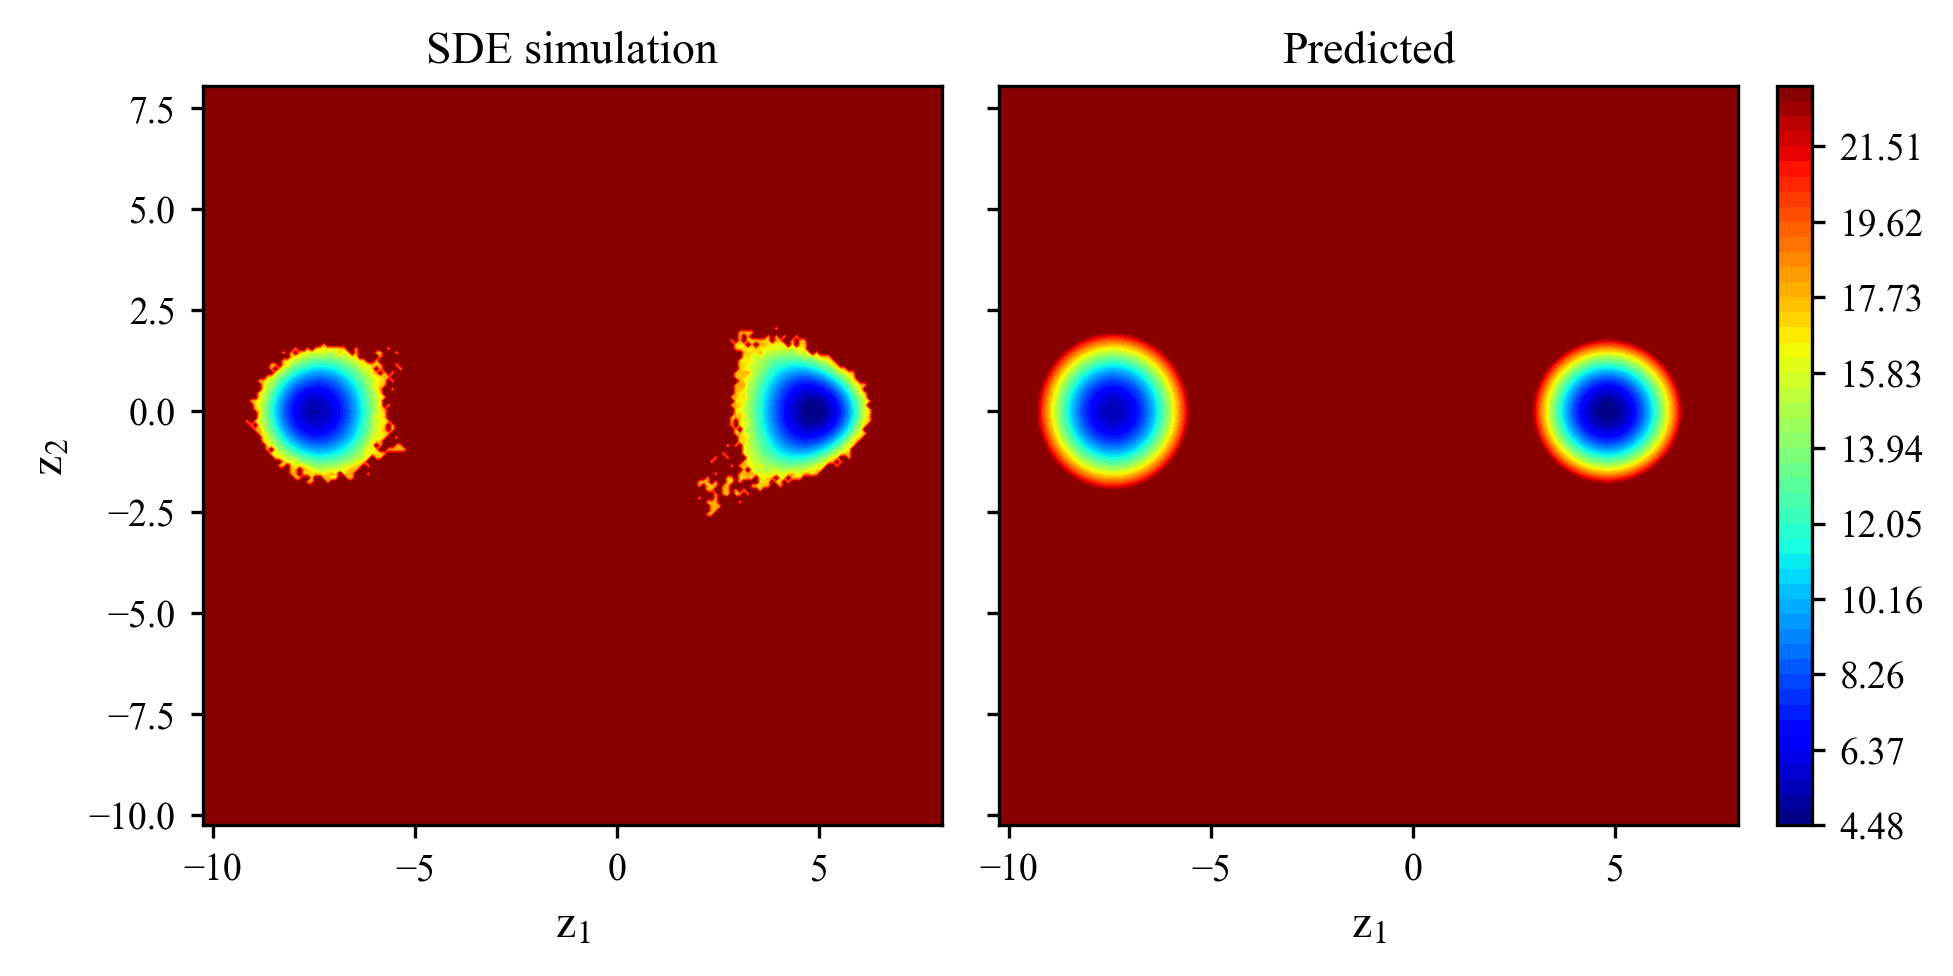

In [8]:
import torch
import torch.nn as nn
import torch.nn.functional as F


# ============================================================
# 1. 定义模型
# ============================================================
class MixtureOfGaussiansModel(nn.Module):
    def __init__(
        self,
        input_dim=5,
        num_components=4,
        hidden_dims=None
    ):
        super(MixtureOfGaussiansModel, self).__init__()

        if hidden_dims is None:
            hidden_dims = [512, 1024, 512]

        self.input_dim = input_dim
        self.num_components = num_components

        self.hidden_layers = nn.ModuleList()

        self.hidden_layers.append(
            nn.Linear(input_dim, hidden_dims[0])
        )

        for i in range(1, len(hidden_dims)):
            self.hidden_layers.append(
                nn.Linear(
                    hidden_dims[i - 1],
                    hidden_dims[i]
                )
            )

        self.output_layer = nn.Linear(
            hidden_dims[-1],
            num_components * 6
        )

    def forward(self, x):
        batch_size = x.shape[0]

        # 隐藏层
        for layer in self.hidden_layers:
            x = F.relu(layer(x))

        # 每个高斯分量输出6个参数
        output = self.output_layer(x)

        output = output.view(
            batch_size,
            self.num_components,
            6
        )

        # 混合权重
        weights = F.softmax(
            output[:, :, 0],
            dim=1
        )

        # 二维高斯均值
        means = output[:, :, 1:3]

        # 协方差矩阵参数
        eps = 1e-6

        s_xx = (
            F.softplus(output[:, :, 3])
            + eps
        )

        alpha = output[:, :, 4]

        rho = (
            2 * torch.sigmoid(alpha)
            - 1
        )

        rho = torch.clamp(
            rho,
            -1 + 1e-4,
            1 - 1e-4
        )

        s_yy = (
            F.softplus(output[:, :, 5])
            + eps
        )

        sigma_xy = rho * torch.sqrt(
            s_xx * s_yy
        )

        covariances = torch.zeros(
            batch_size,
            self.num_components,
            2,
            2,
            device=output.device,
            dtype=output.dtype
        )

        covariances[:, :, 0, 0] = s_xx
        covariances[:, :, 0, 1] = sigma_xy
        covariances[:, :, 1, 0] = sigma_xy
        covariances[:, :, 1, 1] = s_yy

        return weights, means, covariances


print("模型加载完成。")

import torch
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal
from scipy.io import loadmat


# ============================================================
# 0. 论文风格绘图参数
# ============================================================
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['xtick.labelsize'] = 9
plt.rcParams['ytick.labelsize'] = 9
plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 300
plt.rcParams['axes.linewidth'] = 0.8

# 刻度线朝外
plt.rcParams['xtick.direction'] = 'out'
plt.rcParams['ytick.direction'] = 'out'


# ============================================================
# 1. 加载模型
# ============================================================
model = MixtureOfGaussiansModel(
    input_dim=5,
    num_components=4,
    hidden_dims=[512, 1024, 512]
)

model.load_state_dict(
    torch.load(
        'best_model_in5_K4_512-1024-512_testloss0.084797.pth',
        map_location='cpu',
        weights_only=True
    )
)

model.eval()


# ============================================================
# 2. 输入一组参数
# ============================================================
input_params = [3.065039,	2.187109,	1.102148,	0.892383,	0.470508
]

# 必须设置为上述 input_params 对应的测试集样本编号
sample_id = 9

x_input = torch.tensor(
    [input_params],
    dtype=torch.float32
)


# ============================================================
# 3. 读取参考概率密度矩阵
# ============================================================
MAT_PATH = (
    f'density_results_ps_test_n_cells=50000_'
    f'python_edges=0.1/ps_test{{{sample_id}}}.mat'
)

MAT_KEY = 'density'

mat_data = loadmat(MAT_PATH)

if MAT_KEY not in mat_data:
    raise KeyError(
        f"变量 '{MAT_KEY}' 未在文件 {MAT_PATH} 中找到。"
    )

ref_density = mat_data[MAT_KEY].astype(np.float64)

n_y, n_x = ref_density.shape

print(f"参考密度矩阵尺寸: {n_y} × {n_x}")


# ============================================================
# 4. 构造与训练数据一致的非负坐标网格
# ============================================================
# 四基因耦合模型的训练代码中使用0.1网格
grid_step = 0.1

# 非负模型坐标系中的网格中心
x_model = (
    np.arange(n_x) * grid_step
    + grid_step / 2
)

y_model = (
    np.arange(n_y) * grid_step
    + grid_step / 2
)

X_model, Y_model = np.meshgrid(
    x_model,
    y_model,indexing='ij'
)

pos_model = np.dstack(
    (X_model, Y_model)
)


# ============================================================
# 5. 得到模型预测参数
# ============================================================
with torch.no_grad():
    weights, means, covariances = model(x_input)

weights_np = weights[0].cpu().numpy()
means_np = means[0].cpu().numpy()
covariances_np = covariances[0].cpu().numpy()

print("\n预测的混合权重：")
print(weights_np)

print("\n预测的均值，非负训练坐标系：")
print(means_np)

print("\n预测的协方差矩阵：")
print(covariances_np)


# ============================================================
# 6. 在与参考密度相同的网格上计算预测密度
# ============================================================
pred_density = np.zeros_like(
    X_model,
    dtype=np.float64
)

for i in range(len(weights_np)):

    cov_i = covariances_np[i]

    # 防止数值误差导致协方差矩阵非正定
    cov_i = cov_i + np.eye(2) * 1e-8

    rv = multivariate_normal(
        mean=means_np[i],
        cov=cov_i,
        allow_singular=True
    )

    pred_density += (
        weights_np[i]
        * rv.pdf(pos_model)
    )


# ============================================================
# 7. 归一化参考密度和预测密度
# ============================================================
ref_density_normalized = (
    ref_density
    / (ref_density.sum() + 1e-12)
)

pred_density_normalized = (
    pred_density
    / (pred_density.sum() + 1e-12)
)


# ============================================================
# 8. 计算 Hellinger 距离
# ============================================================
hellinger = np.sqrt(
    0.5
    * np.sum(
        (
            np.sqrt(ref_density_normalized)
            - np.sqrt(pred_density_normalized)
        ) ** 2
    )
)

print(
    f"\nHellinger distance = "
    f"{hellinger:.6f}"
)


# ============================================================
# 9. 将网格平移回原始 Xedges / Yedges 坐标
# ============================================================
# 这里填写原始统一网格的Xedges和Yedges最小值。
# 必须是边界最小值，而不是第一个网格中心。

X_MIN = -10.3
Y_MIN = -10.3

# 将非负训练网格平移回原始坐标
X_true = X_model + X_MIN
Y_true = Y_model + Y_MIN

# 将预测均值也平移回原始坐标
means_true = means_np.copy()

means_true[:, 0] = (
    means_true[:, 0]
    + X_MIN
)

means_true[:, 1] = (
    means_true[:, 1]
    + Y_MIN
)

print("\n预测的均值，平移回原始坐标系后：")
print(means_true)


# ============================================================
# 10. 转换为 landscape：U = -log(P)
# ============================================================
eps = 1e-10

ref_landscape = -np.log(
    np.maximum(
        ref_density_normalized,
        eps
    )
)

pred_landscape = -np.log(
    np.maximum(
        pred_density_normalized,
        eps
    )
)


# ============================================================
# 11. 设置两个图统一的颜色范围
# ============================================================
vmin = min(
    ref_landscape.min(),
    pred_landscape.min()
)

vmax = max(
    ref_landscape.max(),
    pred_landscape.max()
)

levels = np.linspace(
    vmin,
    vmax,
    50
)


# ============================================================
# 12. 论文风格绘图
# ============================================================
fig = plt.figure(
    figsize=(7.0, 3.2)
)

gs = fig.add_gridspec(
    1,
    3,
    width_ratios=[1, 1, 0.045],
    wspace=0.04
)

ax1 = fig.add_subplot(
    gs[0, 0]
)

ax2 = fig.add_subplot(
    gs[0, 1]
)

cax = fig.add_subplot(
    gs[0, 2]
)


# ------------------------------------------------------------
# 左图：参考 Landscape
# ------------------------------------------------------------
cf1 = ax1.contourf(
    X_true,
    Y_true,
    ref_landscape,
    levels=levels,
    cmap='jet',
    vmin=vmin,
    vmax=vmax
)


ax1.set_title('SDE simulation', pad=6)
ax1.set_xlabel(r"$\mathrm{z}_1$")
ax1.set_ylabel(r"$\mathrm{z}_2$")
ax1.set_aspect('equal')


# ------------------------------------------------------------
# 右图：预测 Landscape
# ------------------------------------------------------------
cf2 = ax2.contourf(
    X_true,
    Y_true,
    pred_landscape,
    levels=levels,
    cmap='jet',
    vmin=vmin,
    vmax=vmax
)

ax2.set_title(f'Predicted', pad=6)
ax2.set_xlabel(r"$\mathrm{z}_1$")
ax2.set_ylabel('')
ax2.set_aspect('equal')



# ============================================================
# 13. 坐标轴样式
# ============================================================
for ax in [ax1, ax2]:

    ax.tick_params(
        axis='both',
        which='both',
        direction='out',
        bottom=True,
        left=True,
        top=False,
        right=False,
        length=3,
        width=0.8
    )

    for spine in ax.spines.values():
        spine.set_linewidth(0.8)


# 第二张图保留左侧刻度线，
# 但是不显示纵轴数字和纵轴标签
ax2.tick_params(
    axis='y',
    left=True,
    labelleft=False,
    right=False,
    labelright=False,
    direction='out'
)

ax2.set_ylabel('')


# ============================================================
# 14. 共享颜色条
# ============================================================
cbar = fig.colorbar(
    cf2,
    cax=cax
)

# 如需颜色条标题，可以取消下一行注释
# cbar.set_label(r'$U=-\log(P)$', labelpad=6)

cbar.ax.tick_params(
    direction='out',
    length=3,
    width=0.8,
    labelsize=9
)

for spine in cbar.ax.spines.values():
    spine.set_linewidth(0.8)


# ============================================================
# 15. 保存为PDF并显示
# ============================================================
SAVE_FIG = True

if SAVE_FIG:

    pdf_name = (
        f'landscape_test_{sample_id}.pdf'
    )

    plt.savefig(
        pdf_name,
        format='pdf',
        dpi=800,
        bbox_inches='tight',
        pad_inches=0.02,
        facecolor='white',
        transparent=False
    )

    print(
        f"\nPDF 文件已保存为: "
        f"{pdf_name}"
    )

plt.show()